# Génération des données v5 : ciblage d'une ONG avec une grille de points

Ce notebook simule le processus de ciblage tel qu'il se fait sur le terrain :

1. **L'ONG définit ses critères** et leurs points, puis les fait **valider localement** (comité de ciblage, autorités, leaders communautaires).
2. **Les enquêteurs collectent** les données avec un formulaire Kobo.
3. **Un agent applique la grille dans Excel** : il additionne les points, applique les inclusions automatiques et les exclusions, puis décide *éligible* ou *non éligible*.
4. **La liste sort.** Si le budget ne couvre pas tous les éligibles, l'agent les classe par score et retient les premiers.

Le notebook produit `data/ciblage_v5.csv` et la base SQLite `data/ciblage_v5.db`. La base contient les tables `menages`, `grille` (les points), `regles` (seuil, inclusions, exclusions) et `dictionnaire`.
Toute la logique se trouve dans `generateur_ciblage_v5.py`.

> La grille est un **exemple réaliste**, pas celle d'une ONG en particulier. La décision de l'agent est une fonction exacte des réponses : il n'y a pas de bruit.
> Les fichiers de données ne sont pas versionnés dans Git : ce notebook les régénère.

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import generateur_ciblage_v5 as gen

d = gen.generer()
gen.construire_base(d, Path("data/ciblage_v5.db"), Path("data/ciblage_v5.csv"))
print(f"{len(d):,} ménages, {d.shape[1]} colonnes — éligibles : {d.eligible.mean():.1%}")

100,000 ménages, 32 colonnes — éligibles : 27.0%


## La grille de l'agent (table `grille`)

In [2]:
with sqlite3.connect("data/ciblage_v5.db") as con:
    grille = pd.read_sql("SELECT * FROM grille", con)
    regles = pd.read_sql("SELECT * FROM regles", con)
display(regles)
grille

,type,regle
0,inclusion automatique,chef de ménage mineur
1,inclusion automatique,enfant non accompagné hébergé ET chef de ménag...
2,exclusion,salaire régulier
3,exclusion,vivres ou cash reçus dans les 3 derniers mois ...
4,seuil,éligible si score >= 40


,critere,reponse,points
0,statut_menage,deplace depuis moins de 3 mois,15
1,statut_menage,deplace depuis 3 mois ou plus,10
2,statut_menage,retourne,8
3,statut_menage,famille d'accueil,5
4,statut_menage,resident,0
5,chef_menage,femme,6
6,chef_menage,mineur (< 18 ans),12
7,chef_menage,age (>= 60 ans),8
8,taille_menage,1 a 3 personnes,0
9,taille_menage,4 a 6,4


## Contrôles de qualité

In [3]:
pd.Series({
    "tranches d'âge = taille du ménage": ((d.enfants_moins_5 + d.enfants_5_17 + d.adultes_18_59 + d.personnes_60_plus) == d.taille_menage).all(),
    "type d'assistance renseigné ssi assistance reçue": ((d.assistance_3_derniers_mois == "oui") == d.type_assistance_recue.notna()).all(),
    "durée de déplacement renseignée ssi déplacé": ((d.statut_menage == "deplace") == d.duree_deplacement_mois.notna()).all(),
    "décision = formule Excel": (d.eligible == gen.feuille_excel(d)[2]).all(),
}, name="OK").to_frame()

,OK
tranches d'âge = taille du ménage,True
type d'assistance renseigné ssi assistance reçue,True
durée de déplacement renseignée ssi déplacé,True
décision = formule Excel,True


## Ce que produit la feuille Excel

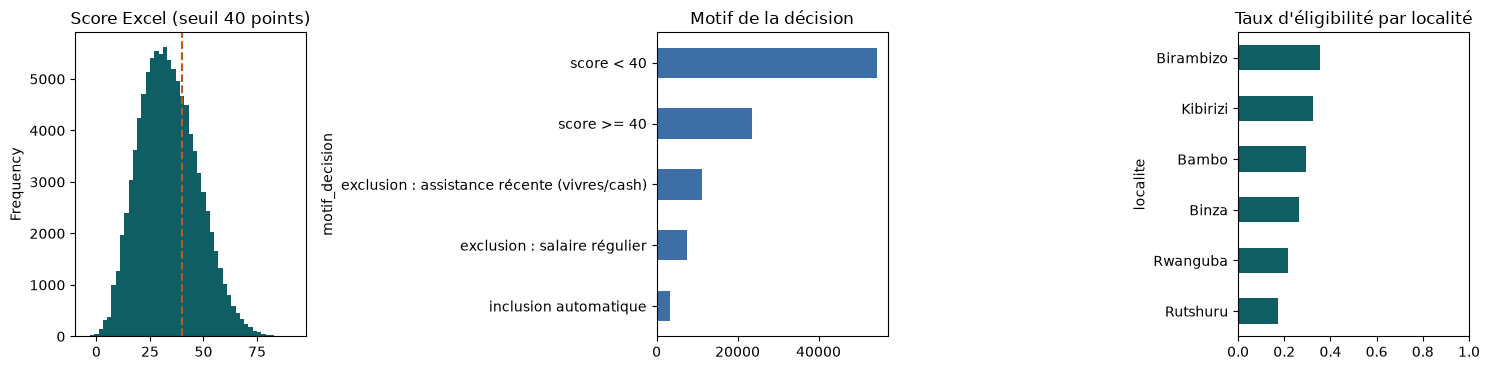

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
d.score_excel.plot.hist(bins=range(-5, 95, 2), ax=axes[0], color="#0f5e63")
axes[0].axvline(gen.SEUIL_ELIGIBILITE, c="#c4551b", ls="--"); axes[0].set_title(f"Score Excel (seuil {gen.SEUIL_ELIGIBILITE} points)")
d.motif_decision.value_counts().iloc[::-1].plot.barh(ax=axes[1], color="#3d6fa6"); axes[1].set_title("Motif de la décision")
d.groupby("localite").eligible.mean().sort_values().plot.barh(ax=axes[2], color="#0f5e63", xlim=(0, 1)); axes[2].set_title("Taux d'éligibilité par localité")
plt.tight_layout(); plt.show()

## Le problème du budget

Prenons **30 % des éligibles** comme capacité de financement. L'agent les classe par score décroissant ; à score égal, le ménage le plus grand passe d'abord, puis le premier enquêté.

In [5]:
rang = gen.classement_excel(d)
budget = int(len(rang) * 0.30)
retenus = d.loc[rang.index[:budget]]
print(f"{len(rang):,} ménages éligibles, budget pour {budget:,} : score minimum retenu = {retenus.score_excel.min()} points")
print(f"Ménages éligibles ayant exactement ce score : {(d.loc[rang.index].score_excel == retenus.score_excel.min()).sum():,} "
      "→ les scores entiers créent beaucoup d'ex aequo, d'où la règle de départage.")

27,046 ménages éligibles, budget pour 8,113 : score minimum retenu = 52 points
Ménages éligibles ayant exactement ce score : 967 → les scores entiers créent beaucoup d'ex aequo, d'où la règle de départage.
